# ML Experiment Results

Generic template notebook: loads every experiment JSON for one greenhouse +
target combination, builds summary tables and plots.

To create one of the four target notebooks (Alava/temperature,
Alava/rel_humidity, Cartagena/temperature, Cartagena/rel_humidity), copy
this notebook and only change `GREENHOUSE` and `TARGET` in the Config cell
below — everything else adapts automatically.


In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 110


## 1. Configuration

In [ ]:
# Greenhouse and target this notebook analyzes.
# GREENHOUSE: "alava" or "cartagena"
# TARGET:     "temperature" or "rel_humidity"
GREENHOUSE = "cartagena"
TARGET = "temperature"

# Base results folder for this greenhouse (one subfolder per model:
# lstm/, gru/, cnn_lstm/, dlinear/, nlinear/, patchtst/, itransformer/).
RESULTS_DIR = Path(f"../results/experiments/{GREENHOUSE}")

# Glob pattern: picks up every model's JSON for the chosen target, e.g.
# results/experiments/alava/lstm/temperature/01_lstm_alava_temp.json
PATTERN = f"*/{TARGET}/*.json"


## 2. Load data

In [3]:
def experiment_name(path: Path) -> str:
    """Experiment name derived from the file name.

    By default uses the file name as-is (without extension). If your
    files include a repetition/seed suffix you want to ignore when
    grouping (e.g. 'my_experiment_seed3.json'), adjust the regex here,
    for example:
        return re.sub(r"_seed\d+$", "", path.stem)
    """
    return path.stem


def load_results(directory: Path, pattern: str = "*.json"):
    """Loads every result JSON into a list of dicts, adding file/experiment
    metadata.

    Supports two file formats:
    - A single results dict per file: {..., "metrics": {...}}
    - A list of results dicts per file: [{...}, {...}, ...]
      (each list element is treated as a distinct repetition/run of the
      same file, and numbered automatically). This is the normal case
      here: each experiment script appends one entry per run to its JSON,
      so a script run 3 times produces a 3-element list.
    """
    files = sorted(Path(directory).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No '{pattern}' files found in {directory}")

    data = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            content = json.load(fh)

        # Normalize to a list of dicts, however the file is shaped
        if isinstance(content, dict):
            items = [content]
        elif isinstance(content, list):
            items = content
        else:
            raise ValueError(f"Unexpected format in {f.name}: expected dict or list, "
                              f"got {type(content)}")

        for i, d in enumerate(items):
            if not isinstance(d, dict):
                raise ValueError(f"Item {i} of {f.name} is not a dict (it's {type(d)})")
            d = dict(d)  # copy so we don't mutate the original
            d["_file"] = f.name if len(items) == 1 else f"{f.name}[{i}]"
            d["_experiment"] = experiment_name(f)
            data.append(d)
    return data


results = load_results(RESULTS_DIR, PATTERN)
print(f"Loaded {len(results)} result files, "
      f"corresponding to {len(set(d['_experiment'] for d in results))} distinct experiment(s).")


Loaded 33 result files, corresponding to 7 distinct experiment(s).


<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
C:\Users\jclps\AppData\Local\Temp\ipykernel_25140\1520848580.py:8: SyntaxWarning: invalid escape sequence '\d'
  return re.sub(r"_seed\d+$", "", path.stem)


## 3. Building the DataFrames

In [4]:
def build_global_df(data):
    rows = []
    for d in data:
        row = {"experiment": d["_experiment"], "file": d["_file"]}
        row.update(d["metrics"]["global"])
        rows.append(row)
    return pd.DataFrame(rows)


def build_horizon_df(data):
    rows = []
    for d in data:
        for h_key, metrics in d["metrics"]["per_horizon"].items():
            row = {
                "experiment": d["_experiment"],
                "file": d["_file"],
                "horizon": int(h_key.split("_")[1]),
            }
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_month_df(data):
    rows = []
    for d in data:
        for month, metrics in d["metrics"].get("per_month", {}).items():
            row = {"experiment": d["_experiment"], "file": d["_file"], "month": month}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


def build_day_night_df(data):
    rows = []
    for d in data:
        for period in ("day", "night"):
            metrics = d["metrics"].get(period)
            if metrics:
                row = {"experiment": d["_experiment"], "file": d["_file"], "period": period}
                row.update(metrics)
                rows.append(row)
    return pd.DataFrame(rows)


df_global = build_global_df(results)
df_horizon = build_horizon_df(results)
df_month = build_month_df(results)
df_day_night = build_day_night_df(results)

df_global.head()


,experiment,file,r2,mse,rmse,mae,mape,relative_error,relative_error_abs
0,05_cnn_lstm_cartagena_temp,05_cnn_lstm_cartagena_temp.json[0],0.887,5.181,2.276,1.461,7.551,-0.006,0.076
1,05_cnn_lstm_cartagena_temp,05_cnn_lstm_cartagena_temp.json[1],0.889,5.085,2.255,1.461,7.691,0.003,0.077
2,05_cnn_lstm_cartagena_temp,05_cnn_lstm_cartagena_temp.json[2],0.879,5.525,2.351,1.542,8.253,0.004,0.083
3,05_cnn_lstm_cartagena_temp,05_cnn_lstm_cartagena_temp.json[3],0.886,5.217,2.284,1.482,7.880,0.007,0.079
4,05_cnn_lstm_cartagena_temp,05_cnn_lstm_cartagena_temp.json[4],0.884,5.328,2.308,1.479,7.766,0.008,0.078


## 4. Global metrics table (mean ± std per experiment)

In [5]:
GLOBAL_METRICS = ["r2", "mse", "rmse", "mae", "mape"]  #, "relative_error", "relative_error_abs"]

global_table = (
    df_global
    .groupby("experiment")[GLOBAL_METRICS]
    .agg(["mean", "std"])
    .round(4)
)

# Flatten the multi-index columns, e.g. ('r2', 'mean') -> 'r2_mean'
global_table.columns = [f"{metric}_{stat}" for metric, stat in global_table.columns]
global_table = global_table.sort_index()
global_table


,r2_mean,r2_std,mse_mean,mse_std,rmse_mean,rmse_std,mae_mean,mae_std,mape_mean,mape_std
experiment,,,,,,,,,,
01_lstm_cartagena_temp,0.884,0.003,5.307,0.132,2.304,0.029,1.499,0.016,7.899,0.107
03_gru_cartagena_temp,0.891,0.004,4.990,0.176,2.233,0.040,1.445,0.042,7.716,0.265
05_cnn_lstm_cartagena_temp,0.885,0.004,5.267,0.168,2.295,0.036,1.485,0.033,7.828,0.266
07_dlinear_cartagena,0.924,0.001,3.480,0.034,1.865,0.009,1.228,0.012,6.586,0.080
08_nlinear_cartagena,0.925,0.000,3.454,0.018,1.859,0.005,1.217,0.004,6.479,0.032
09_patchtst_cartagena,0.928,0.003,3.315,0.157,1.820,0.043,1.220,0.028,6.463,0.200
10_itransformer_cartagena,0.934,0.002,3.040,0.072,1.744,0.021,1.089,0.020,5.449,0.088


### Compact 'mean ± std' version, easier to read

In [6]:
def mean_std_table(df, metrics, group_cols):
    agg = df.groupby(group_cols)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        mean = agg[(m, "mean")]
        std = agg[(m, "std")].fillna(0)
        out[m] = [f"{mu:.3f} \u00b1 {sd:.3f}" for mu, sd in zip(mean, std)]
    return out.sort_index()


compact_global_table = mean_std_table(df_global, GLOBAL_METRICS, ["experiment"])
compact_global_table


,r2,mse,rmse,mae,mape
experiment,,,,,
01_lstm_cartagena_temp,0.884 ± 0.003,5.307 ± 0.132,2.304 ± 0.029,1.499 ± 0.016,7.899 ± 0.107
03_gru_cartagena_temp,0.891 ± 0.004,4.990 ± 0.176,2.233 ± 0.040,1.445 ± 0.042,7.716 ± 0.265
05_cnn_lstm_cartagena_temp,0.885 ± 0.004,5.267 ± 0.168,2.295 ± 0.037,1.485 ± 0.033,7.828 ± 0.266
07_dlinear_cartagena,0.924 ± 0.001,3.480 ± 0.034,1.865 ± 0.009,1.228 ± 0.012,6.586 ± 0.080
08_nlinear_cartagena,0.925 ± 0.000,3.454 ± 0.018,1.859 ± 0.005,1.217 ± 0.004,6.479 ± 0.032
09_patchtst_cartagena,0.928 ± 0.003,3.315 ± 0.157,1.820 ± 0.043,1.220 ± 0.028,6.463 ± 0.200
10_itransformer_cartagena,0.934 ± 0.002,3.040 ± 0.072,1.743 ± 0.021,1.089 ± 0.020,5.448 ± 0.088


In [7]:
compact_global_table.to_latex()


'\\begin{tabular}{llllll}\n\\toprule\n & r2 & mse & rmse & mae & mape \\\\\nexperiment &  &  &  &  &  \\\\\n\\midrule\n01_lstm_cartagena_temp & 0.884 ± 0.003 & 5.307 ± 0.132 & 2.304 ± 0.029 & 1.499 ± 0.016 & 7.899 ± 0.107 \\\\\n03_gru_cartagena_temp & 0.891 ± 0.004 & 4.990 ± 0.176 & 2.233 ± 0.040 & 1.445 ± 0.042 & 7.716 ± 0.265 \\\\\n05_cnn_lstm_cartagena_temp & 0.885 ± 0.004 & 5.267 ± 0.168 & 2.295 ± 0.037 & 1.485 ± 0.033 & 7.828 ± 0.266 \\\\\n07_dlinear_cartagena & 0.924 ± 0.001 & 3.480 ± 0.034 & 1.865 ± 0.009 & 1.228 ± 0.012 & 6.586 ± 0.080 \\\\\n08_nlinear_cartagena & 0.925 ± 0.000 & 3.454 ± 0.018 & 1.859 ± 0.005 & 1.217 ± 0.004 & 6.479 ± 0.032 \\\\\n09_patchtst_cartagena & 0.928 ± 0.003 & 3.315 ± 0.157 & 1.820 ± 0.043 & 1.220 ± 0.028 & 6.463 ± 0.200 \\\\\n10_itransformer_cartagena & 0.934 ± 0.002 & 3.040 ± 0.072 & 1.743 ± 0.021 & 1.089 ± 0.020 & 5.448 ± 0.088 \\\\\n\\bottomrule\n\\end{tabular}\n'

## 5. Metrics table by month and by day/night

In [8]:
MONTH_METRICS = ["r2", "mse", "rmse", "mae", "mape"]

month_table = mean_std_table(df_month, MONTH_METRICS, ["experiment", "month"])
month_table


r2             mse  \
experiment                month                                    
01_lstm_cartagena_temp    2025-07  0.965 ± 0.004   0.347 ± 0.037   
                          2025-08  0.877 ± 0.011   2.296 ± 0.209   
                          2025-09  0.810 ± 0.011   5.462 ± 0.323   
                          2025-10  0.719 ± 0.011  10.194 ± 0.385   
                          2025-11  0.899 ± 0.007   3.295 ± 0.220   
...                                          ...             ...   
10_itransformer_cartagena 2025-11  0.918 ± 0.003   2.680 ± 0.100   
                          2025-12  0.871 ± 0.005   3.275 ± 0.135   
                          2026-01  0.885 ± 0.004   2.771 ± 0.087   
                          2026-02  0.913 ± 0.001   2.292 ± 0.038   
                          2026-03  0.572 ± 0.157   1.506 ± 0.554   

                                            rmse            mae           mape  
experiment                month                                                 
01_lstm_cartagena_temp    2025-07  0.588 ± 0.032  0.466 ± 0.025  1.881 ± 0.078  
                          2025-08  1.514 ± 0.070  1.051 ± 0.043  3.946 ± 0.162  
                          2025-09  2.336 ± 0.070  1.585 ± 0.029  5.825 ± 0.118  
                          2025-10  3.192 ± 0.060  1.785 ± 0.043  6.916 ± 0.143  
                          2025-11  1.814 ± 0.060  1.233 ± 0.052  7.579 ± 0.441  
...                                          ...            ...            ...  
10_itransformer_cartagena 2025-11  1.637 ± 0.031  1.115 ± 0.026  6.440 ± 0.128  
                          2025-12  1.809 ± 0.037  1.198 ± 0.027  6.946 ± 0.109  
                          2026-01  1.664 ± 0.026  1.079 ± 0.017  6.476 ± 0.059  
                          2026-02  1.514 ± 0.012  1.032 ± 0.008  6.025 ± 0.091  
                          2026-03  1.214 ± 0.218  0.940 ± 0.144  6.542 ± 0.919  

[62 rows x 5 columns]

In [9]:
DAY_NIGHT_METRICS = ["r2", "mse", "rmse", "mae", "mape", "relative_error", "relative_error_abs"]

day_night_table = mean_std_table(df_day_night, DAY_NIGHT_METRICS, ["experiment", "period"])
day_night_table


r2            mse  \
experiment                 period                                 
01_lstm_cartagena_temp     day     0.836 ± 0.006  9.028 ± 0.322   
                           night   0.922 ± 0.003  2.189 ± 0.073   
03_gru_cartagena_temp      day     0.846 ± 0.005  8.460 ± 0.268   
                           night   0.926 ± 0.006  2.081 ± 0.174   
05_cnn_lstm_cartagena_temp day     0.836 ± 0.004  9.019 ± 0.215   
                           night   0.924 ± 0.007  2.123 ± 0.198   
07_dlinear_cartagena       day     0.910 ± 0.001  4.939 ± 0.042   
                           night   0.919 ± 0.001  2.260 ± 0.034   
08_nlinear_cartagena       day     0.911 ± 0.001  4.922 ± 0.064   
                           night   0.920 ± 0.001  2.227 ± 0.024   
09_patchtst_cartagena      day     0.919 ± 0.003  4.505 ± 0.149   
                           night   0.917 ± 0.006  2.326 ± 0.166   
10_itransformer_cartagena  day     0.915 ± 0.003  4.693 ± 0.158   
                           night   0.941 ± 0.002  1.658 ± 0.049   

                                            rmse            mae  \
experiment                 period                                 
01_lstm_cartagena_temp     day     3.004 ± 0.054  2.067 ± 0.040   
                           night   1.479 ± 0.025  1.023 ± 0.016   
03_gru_cartagena_temp      day     2.908 ± 0.046  1.994 ± 0.056   
                           night   1.441 ± 0.061  0.986 ± 0.037   
05_cnn_lstm_cartagena_temp day     3.003 ± 0.036  2.063 ± 0.038   
                           night   1.456 ± 0.066  1.001 ± 0.052   
07_dlinear_cartagena       day     2.222 ± 0.009  1.466 ± 0.013   
                           night   1.503 ± 0.011  1.029 ± 0.015   
08_nlinear_cartagena       day     2.219 ± 0.014  1.460 ± 0.016   
                           night   1.492 ± 0.008  1.015 ± 0.008   
09_patchtst_cartagena      day     2.122 ± 0.035  1.436 ± 0.025   
                           night   1.524 ± 0.053  1.041 ± 0.031   
10_itransformer_cartagena  day     2.166 ± 0.037  1.374 ± 0.027   
                           night   1.288 ± 0.019  0.851 ± 0.028   

                                             mape  relative_error  \
experiment                 period                                   
01_lstm_cartagena_temp     day     10.075 ± 0.240   0.019 ± 0.003   
                           night    6.075 ± 0.076  -0.013 ± 0.007   
03_gru_cartagena_temp      day      9.914 ± 0.355   0.027 ± 0.006   
                           night    5.873 ± 0.215  -0.006 ± 0.004   
05_cnn_lstm_cartagena_temp day     10.084 ± 0.370   0.021 ± 0.008   
                           night    5.938 ± 0.323  -0.011 ± 0.004   
07_dlinear_cartagena       day      6.956 ± 0.086   0.020 ± 0.002   
                           night    6.277 ± 0.108   0.022 ± 0.004   
08_nlinear_cartagena       day      6.875 ± 0.107   0.016 ± 0.002   
                           night    6.149 ± 0.041   0.018 ± 0.001   
09_patchtst_cartagena      day      6.781 ± 0.200   0.021 ± 0.008   
                           night    6.199 ± 0.202   0.021 ± 0.009   
10_itransformer_cartagena  day      6.005 ± 0.094  -0.007 ± 0.001   
                           night    4.983 ± 0.152   0.008 ± 0.007   

                                  relative_error_abs  
experiment                 period                     
01_lstm_cartagena_temp     day         0.101 ± 0.002  
                           night       0.061 ± 0.001  
03_gru_cartagena_temp      day         0.099 ± 0.004  
                           night       0.059 ± 0.002  
05_cnn_lstm_cartagena_temp day         0.101 ± 0.004  
                           night       0.059 ± 0.003  
07_dlinear_cartagena       day         0.070 ± 0.001  
                           night       0.063 ± 0.001  
08_nlinear_cartagena       day         0.069 ± 0.001  
                           night       0.061 ± 0.000  
09_patchtst_cartagena      day         0.068 ± 0.002  
                           night       0.062 ± 0.002  
10_itransformer_cartagena

## 6. Metric evolution across the prediction horizon

`plot_metric_by_horizon` plots a single metric for one or more experiments.
If an experiment has several repetitions (same `experiment`, different
files), the mean is drawn together with a shaded band of ± 1 standard
deviation.

The following cell (`plot_all_metrics_by_horizon`) reuses the same logic to
draw **every metric at once**, as a grid of subplots, so a single cell
produces the full picture instead of one plot per cell.


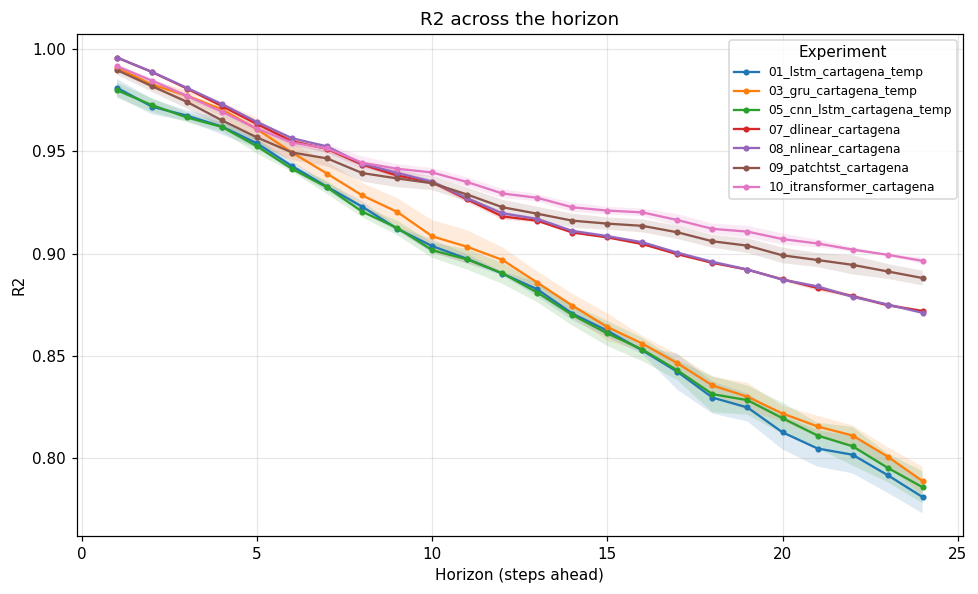

In [10]:
def plot_metric_by_horizon(df_horizon, experiments=None, metric="r2", ax=None,
                            figsize=(9, 5.5), title=None):
    """Plots the evolution of one metric (default r2) across the prediction
    horizon, for one or more experiments.

    Parameters
    ----------
    df_horizon : DataFrame returned by build_horizon_df
    experiments : str, list of str, or None (None = every available experiment)
    metric : metric column name to plot ('r2', 'mae', 'rmse', 'mape', ...)
    """
    if experiments is None:
        experiments = sorted(df_horizon["experiment"].unique())
    elif isinstance(experiments, str):
        experiments = [experiments]

    owns_figure = ax is None
    if owns_figure:
        fig, ax = plt.subplots(figsize=figsize)

    for experiment in experiments:
        subset = df_horizon[df_horizon["experiment"] == experiment]
        agg = subset.groupby("horizon")[metric].agg(["mean", "std"]).sort_index()
        ax.plot(agg.index, agg["mean"], marker="o", markersize=3, label=experiment)
        std = agg["std"].fillna(0)
        if (std > 0).any():
            ax.fill_between(agg.index, agg["mean"] - std, agg["mean"] + std, alpha=0.15)

    ax.set_xlabel("Horizon (steps ahead)")
    ax.set_ylabel(metric.upper() if metric in ("r2", "mae", "mse", "rmse") else metric)
    ax.set_title(title or f"{metric.upper()} across the horizon")
    ax.grid(alpha=0.3)
    ax.legend(title="Experiment", fontsize=8)
    if owns_figure:
        plt.tight_layout()
    return ax


plot_metric_by_horizon(df_horizon)
plt.show()


### All metrics at once

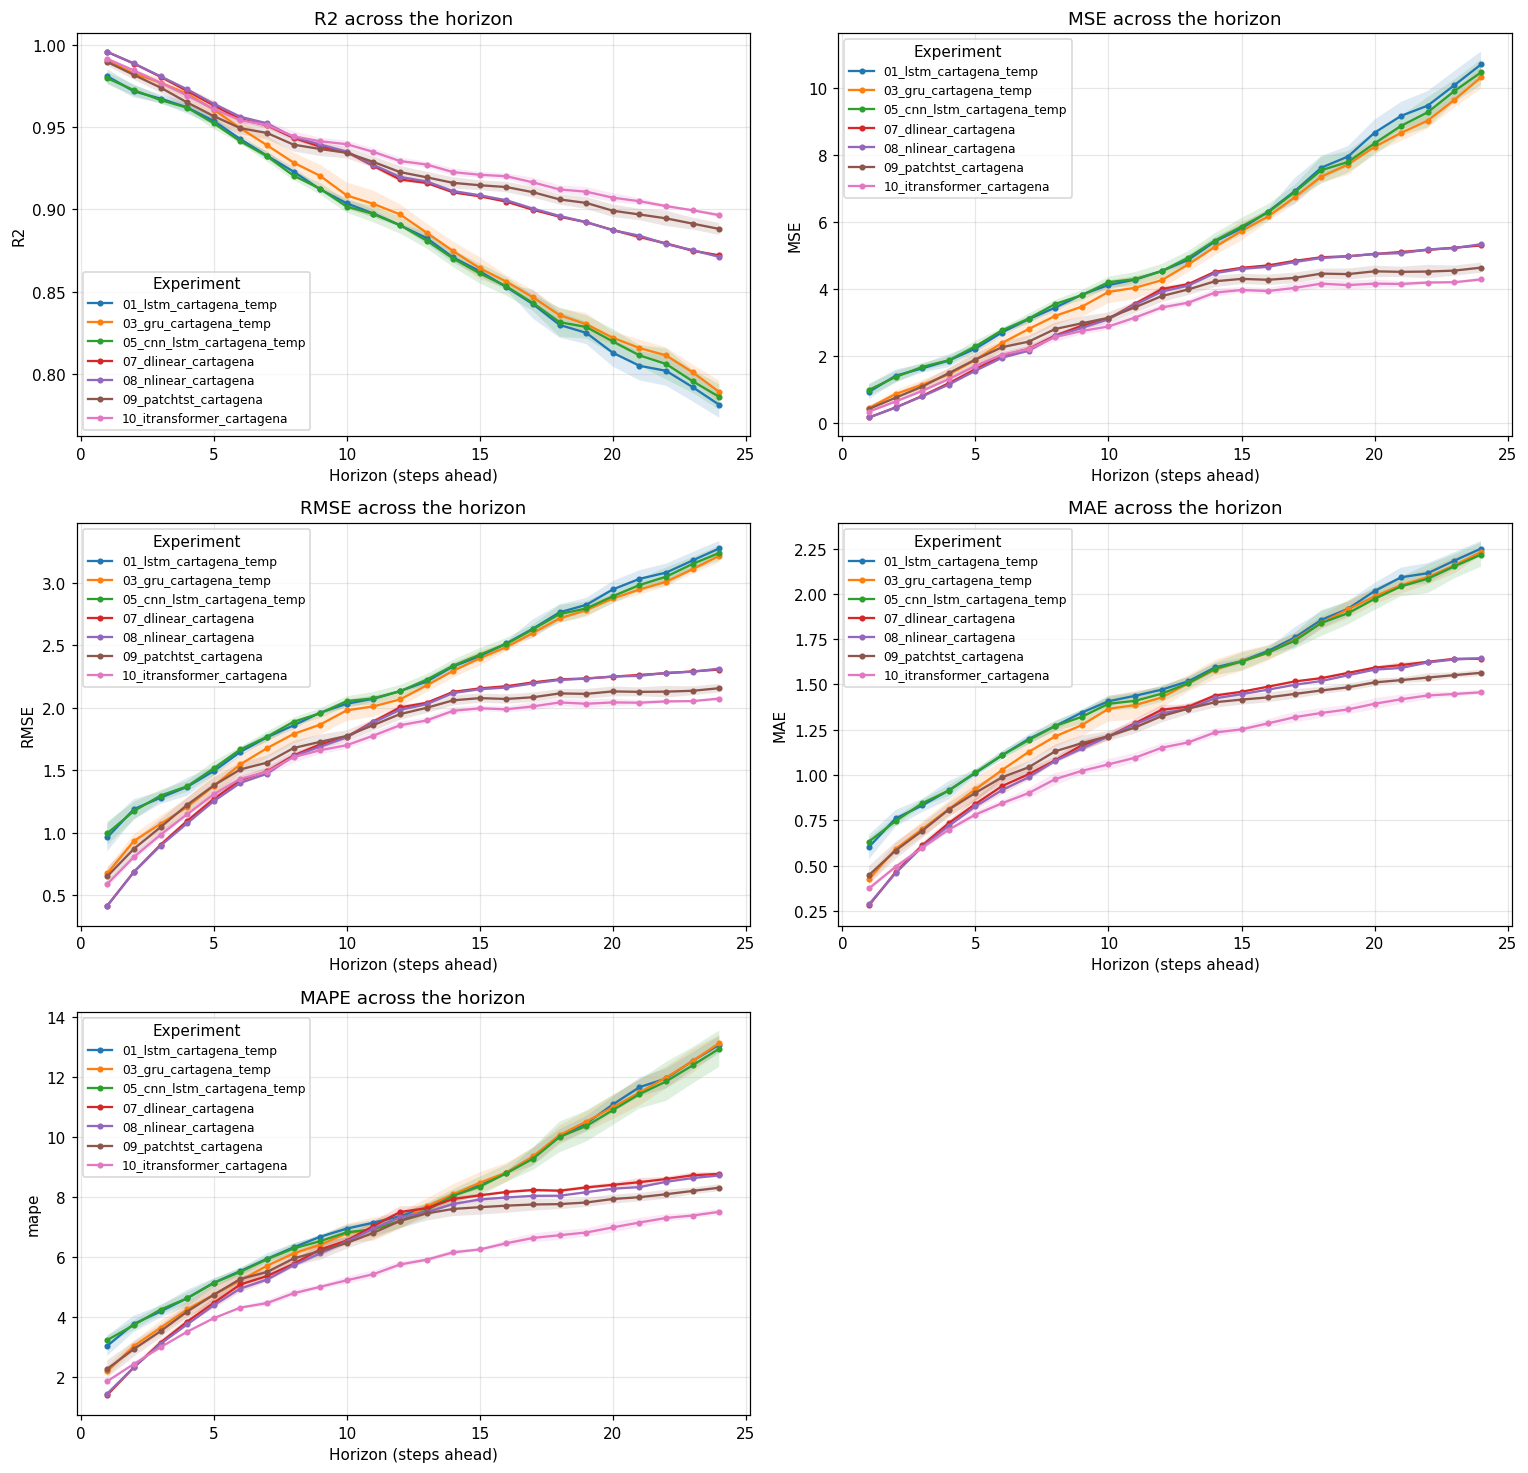

In [11]:
def plot_all_metrics_by_horizon(df_horizon, experiments=None,
                                 metrics=GLOBAL_METRICS, ncols=2, figsize=(7, 4.5)):
    """Draws one subplot per metric (all of GLOBAL_METRICS by default), each
    showing every experiment, in a single figure - the one-cell replacement
    for calling plot_metric_by_horizon once per metric.
    """
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        plot_metric_by_horizon(df_horizon, experiments=experiments, metric=metric, ax=ax)

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


plot_all_metrics_by_horizon(df_horizon)
plt.show()
